# Appendix: selected sets across the constraint range

The myopic rule and the horizon-optimized schedule, side by side, at
five constraint levels in each setting. Left column minimizes the terminal
generalization error under a query budget $\gamma$, right column minimizes the
cumulative cost at query price $\Delta$. The constraint tightens downward:
$\gamma$ decreases, since a larger budget allows more queries, and $\Delta$
increases, since a dearer query buys less.

Both parameter grids are equispaced strictly inside their ranges,
$0<\gamma<1$ and $0<\Delta<1/2$, and coincide with points already solved in
`02_budget` and `03_cost`, so the optimized policies are reused and only the
selection maps are computed here.

Set `RECOMPUTE = True` to redo them (about 9 min).

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import adatron as A, optimize as O, plotting as P

RECOMPUTE = False
p = A.Params()
GAMMAS = np.array([0.9, 0.7, 0.5, 0.3, 0.1])        # top to bottom: tighter
DELTAS = np.array([0.05, 0.15, 0.25, 0.35, 0.45])   # top to bottom: tighter
os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)

In [2]:
if RECOMPUTE or not os.path.exists('results/selgrid.npz'):
    bud = dict(np.load('results/budget.npz'))
    cos = dict(np.load('results/cost.npz'))
    out = {'gammas': GAMMAS, 'deltas': DELTAS}
    for r, g in enumerate(GAMMAS):
        i = int(np.argmin(np.abs(bud['gammas'] - g)))
        t, lo, hi = O.local_support_trace(p, float(bud['nu'][i]))
        a, b = O.refine_schedule(p, bud['a_sched'][i], bud['b_sched'][i],
                                 'budget', gamma=float(g))
        out['b_t%d' % r], out['b_lo%d' % r], out['b_hi%d' % r] = t, lo, hi
        out['b_a%d' % r], out['b_b%d' % r] = a, b
        print('budget gamma=%.1f done' % g, flush=True)
    # the horizon-optimized cost policy is searched over both radii, so that
    # its collapse to a_t = 0 comes out of the optimization
    for r, d in enumerate(DELTAS):
        i = int(np.argmin(np.abs(cos['deltas'] - d)))
        out['c_loc%d' % r] = O.local_cost_kappa(p, float(d), n=400)
        out['c_a%d' % r], out['c_b%d' % r] = O.refine_schedule(
            p, cos['a_sched'][i], cos['b_sched'][i], 'cost', delta=float(d))
        print('cost Delta=%.2f done' % d, flush=True)
    np.savez('results/selgrid.npz', **out)

S = dict(np.load('results/selgrid.npz'))
print('local outer radius, largest over all budget panels: %.2f'
      % max(np.nanmax(S['b_hi%d' % r]) for r in range(len(GAMMAS))))
print('cost panels, largest inner radius over both radii: %.2e'
      % max(S['c_a%d' % r].max() for r in range(len(DELTAS))))

local outer radius, largest over all budget panels: 3.10
cost panels, largest inner radius over both radii: 0.00e+00


## Figure

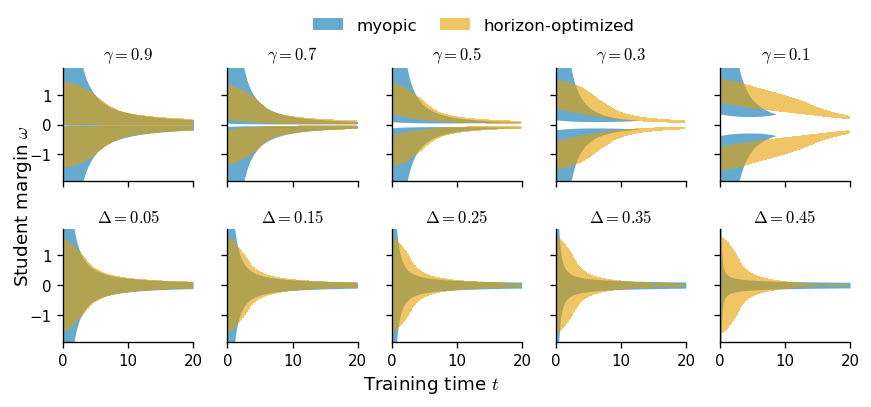

In [3]:
def times(n):
    return (p.t_F / n) * np.arange(n)

budget_panels = []
for r, g in enumerate(GAMMAS):
    a, b = S['b_a%d' % r], S['b_b%d' % r]
    budget_panels.append((
        r'$\gamma = %.1f$' % g,
        P.Band(S['b_t%d' % r], S['b_lo%d' % r], S['b_hi%d' % r],
               step=False, mirror=True),
        P.Band(times(len(a)), a, b, step=True, mirror=True)))

cost_panels = []
for r, d in enumerate(DELTAS):
    kloc, a, b = S['c_loc%d' % r], S['c_a%d' % r], S['c_b%d' % r]
    cost_panels.append((
        r'$\Delta = %.2f$' % d,
        P.Band(times(len(kloc)), -kloc, kloc, step=False, mirror=False),
        P.Band(times(len(a)), a, b, step=True, mirror=True)))

fig, axes = P.selection_grid(budget_panels, cost_panels, p.t_F,
                             omega_max=1.9)
fig.savefig('figures/fig_sel_grid.pdf')